# Aula 26 — KD-Trees

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O SCADA apresenta um mapa e precisa localizar pontos próximos à posição recebida: entradas de talhão, base e ocorrências georreferenciadas. A KD-Tree indexa coordenadas e permite consultas de vizinho mais próximo ou de todos os pontos dentro de um raio.

Nesta etapa ela atua como serviço de consulta espacial do servidor. Na Aula 28, o replay usa a posição do cenário para identificar o ponto cadastrado mais próximo. O índice não decide a viabilidade de deslocamento e não considera obstáculos.

## 2. Modelo e fundamentação

Uma KD-Tree divide o conjunto por eixos alternados. Em 2D, a raiz usa x, o nível seguinte y, depois x novamente. Construímos pela mediana, preservando um identificador distinto para pontos coincidentes. A implementação ordena a cada nível, com construção $O(n\log^2 n)$ e memória de nós $O(n)$, além das listas temporárias.

Na busca exata, visitamos primeiro o lado da consulta. O outro lado só pode ser descartado quando a distância ao plano de divisão é maior que a melhor distância encontrada. Usamos a comparação inclusiva no empate para preservar o menor ID. A poda é justificada pelo limite inferior da distância ao plano, não pela distância a um ponto arbitrário.

Em dados favoráveis e baixa dimensão, muitas consultas visitam poucos nós; o pior caso continua $O(n)$. A consulta por raio usa poda semelhante e pode retornar vários IDs. Distâncias são euclidianas em metros locais, não graus de latitude/longitude.

## 3. Procedimento e demonstração

1. Construir a árvore dos pontos do mapa e mostrar os eixos de divisão.
2. Buscar o vizinho de uma posição de consulta.
3. Comparar 100 consultas em 402 pontos com busca exaustiva.
4. Validar consulta por raio, árvore vazia e coordenadas duplicadas.
5. Contar nós examinados em vez de prometer ganho baseado em poucos microssegundos.

Pergunta para a apresentação: o ponto mais próximo é sempre o mais fácil de alcançar? Não. Obstáculos, condições operacionais e recursos podem invalidar a escolha.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
def kd_construir(pontos, profundidade=0):
    """Recebe pares (ID, ponto); IDs distintos preservam pontos coincidentes."""
    if not pontos: return None
    eixo = profundidade % 2
    ordenados = sorted(pontos, key=lambda x: (x[1][eixo], x[0])); m = len(ordenados)//2
    ident, p = ordenados[m]
    return NoKD(ident, tuple(p), eixo, kd_construir(ordenados[:m], profundidade+1),
                kd_construir(ordenados[m+1:], profundidade+1))


def kd_vizinho(raiz, consulta):
    melhor = (math.inf, math.inf, None); visitas = 0
    def visitar(no):
        nonlocal melhor, visitas
        if no is None: return
        visitas += 1; d2 = sum((a-b)**2 for a, b in zip(no.ponto, consulta))
        candidato = (d2, no.id, no.ponto)
        if candidato[:2] < melhor[:2]: melhor = candidato
        delta = consulta[no.eixo]-no.ponto[no.eixo]
        perto, longe = (no.esq, no.dir) if delta < 0 else (no.dir, no.esq)
        visitar(perto)
        if delta*delta <= melhor[0]: visitar(longe)  # igualdade preserva desempate por ID
    visitar(raiz)
    return (None if melhor[2] is None else (melhor[1], melhor[2], math.sqrt(melhor[0]))), visitas


def kd_raio(raiz, consulta, raio):
    if raio < 0: raise ValueError('Raio negativo')
    resultado = []
    def visitar(no):
        if no is None: return
        if math.dist(no.ponto, consulta) <= raio: resultado.append(no.id)
        delta = consulta[no.eixo]-no.ponto[no.eixo]
        if delta <= raio: visitar(no.esq)
        if delta >= -raio: visitar(no.dir)
    visitar(raiz); return sorted(resultado)


### Índice espacial e consulta no mapa

Ponto: T2 | distância: 25.0 m | visitas: 5
IDs dentro de 60 m: [2, 5]


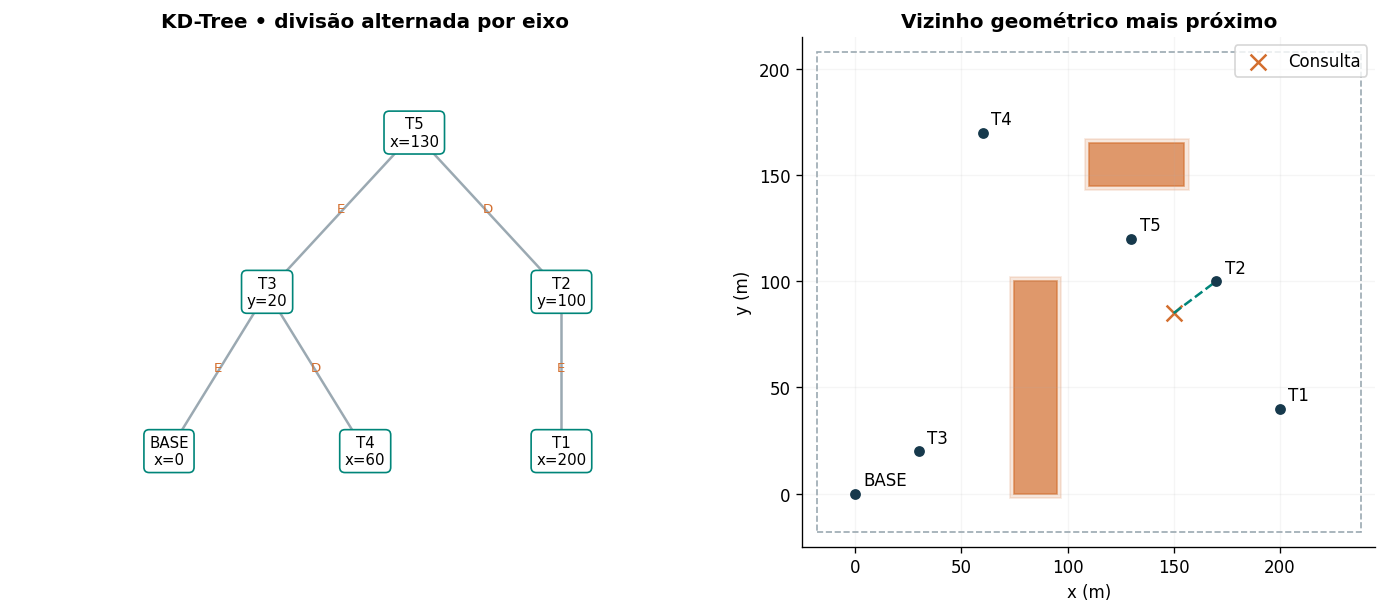

In [3]:
nomes=list(PONTOS);tree=kd_construir(list(enumerate(PONTOS.values())))
vizinho,visitas=kd_vizinho(tree,(150,85))
print('Ponto:',nomes[vizinho[0]],'| distância:',vizinho[2],'m | visitas:',visitas)
print('IDs dentro de 60 m:',kd_raio(tree,(150,85),60))
vis.figura26();plt.show()

### Referência exaustiva e casos degenerados

In [4]:
r=TESTES[26]()
print('100 consultas conferidas contra busca exaustiva:',r)
print('Coordenadas duplicadas mantêm IDs; empate usa o menor ID.')

100 consultas conferidas contra busca exaustiva: {'consultas': 100, 'pontos': 402, 'media_nos_visitados': 14.2}
Coordenadas duplicadas mantêm IDs; empate usa o menor ID.


### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [5]:
RESUMO = TESTES[26]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 26: APROVADAS')

{
  "consultas": 100,
  "pontos": 402,
  "media_nos_visitados": 14.2
}
Verificações da aula 26: APROVADAS


## 5. Interpretação, limites e continuidade

Este índice é estático; a inserção de novos pontos exige reconstrução no exemplo. Atualizar uma KD-Tree durante o crescimento de um RRT requer política adicional de reconstrução ou buffer de pontos. O RRT desta entrega continua explicitamente linear; não se atribui à Aula 22 um ganho não implementado.

Coordenadas coincidentes têm IDs distintos e os empates são determinísticos. Antes de usar uma posição na HMI, a camada supervisória deve verificar a qualidade do GPS. A árvore apenas responde à consulta geométrica.

## 6. Referências

- [SciPy — KDTree](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.KDTree.html).
- [SciPy — consulta de vizinhos](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.KDTree.query.html). As funções da entrega são implementações próprias, sem dependência de SciPy.